# Bestiario de mazmorra: criaturas nuevas con una GAN

**Proyecto 2 · Diseño generativo de personajes** · Deep Learning 2026 · Universidad del Valle

Integrantes: _Erick Guerra_ · _Carlos Alburez_

Este notebook entrena una GAN que crea criaturas de fantasía que no existen. Cubre el universo, los datos, el modelo, dos experimentos, la galería final y la prueba de que las criaturas son nuevas.

Para ejecutarlo en Google Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU*, y luego *Ejecutar todo*.

## 0. Preparación

In [5]:
import os, random
import numpy as np
import torch

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Dispositivo:", device)

CONFIG = {
    "img_size": 64,        # tamaño de las imágenes
    "nz": 100,             # tamaño del vector de ruido
    "batch_size": 64,
    "epochs": 300,         # se fija después de la prueba de 2 épocas
    "lr_g": 2e-4,
    "lr_d": 2e-4,
    "beta1": 0.5,
    "loss": "bce",         # "bce" (no saturante) o "hinge"
    "spectral_norm": False,
    "n_fixed": 16,         # vectores de ruido fijos para la rejilla
    "out_dir": "salidas",
}

os.makedirs(CONFIG["out_dir"], exist_ok=True)


Dispositivo: cuda


## 1. El universo

Un **bestiario de mazmorra**: criaturas hostiles de fantasía oscura (bestias, no muertos, demonios, plantas y hongos, seres amorfos y de tentáculos), dibujadas en pixel art con contorno oscuro y una paleta limitada.

Esperamos ver un monstruo por imagen, centrado, con una silueta clara y rasgos reconocibles como ojos, garras o extremidades, sin fondo.

Con esta descripción juzgaremos la galería final:
- **Silueta legible:** se distingue una criatura.
- **Estilo coherente:** contorno oscuro y paleta limitada, como en los datos.
- **Variedad:** las criaturas se diferencian entre sí en forma, color y tipo.

## 2. Los datos

**Origen:** sprites de monstruos del juego [Dungeon Crawl Stone Soup](https://github.com/crawl/crawl), carpeta `crawl-ref/source/rltiles/mon`.

**Licencia:** el repositorio declara que la mayoría de sus tiles son CC0 (dominio público). Los monstruos del juego se tratan aquí como material de estilo y se citan; la galería final se compara con ellos para comprobar que no los copia.

**Preparación:**
- Se excluyen las carpetas de jugador, modo sprint, vaults y monstruos únicos (personajes con nombre propio).
- Se usan solo las imágenes de 32 × 32 y se eliminan las repetidas.
- Los fondos transparentes se rellenan con gris neutro.
- Se amplían a 64 × 64 sin suavizar, para conservar el pixel art.
- Los valores de color se llevan al rango [−1, 1].
- Aumento de datos al entrenar: volteo horizontal y desplazamiento de hasta 2 píxeles.

Sprites en las carpetas elegidas: 1416
Imágenes únicas de 32 × 32: 1335 | forma: (1335, 3, 64, 64)


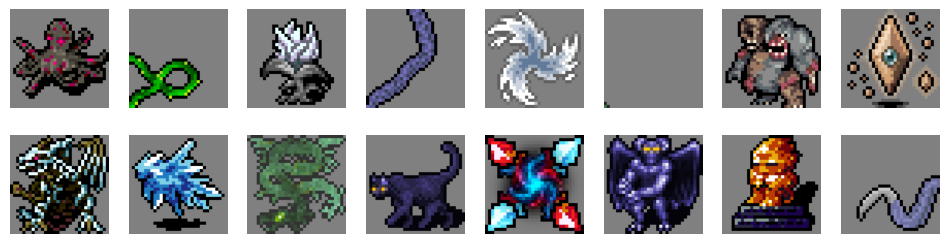

Imágenes en el conjunto de entrenamiento: 1335


In [6]:
import io, zipfile, urllib.request, hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

CRAWL_COMMIT = "034f1973d3d05beef63cc8987ddb7e7f490eea2c"
CRAWL_ZIP = f"https://github.com/crawl/crawl/archive/{CRAWL_COMMIT}.zip"
PREFIJO = f"crawl-{CRAWL_COMMIT}/crawl-ref/source/rltiles/mon/"
CARPETAS = ["aberrations", "abyss", "amorphous", "animals", "aquatic", "demihumanoids",
            "demons", "draco", "dragons", "eyes", "fungi_plants", "holy", "humanoids",
            "mutantbeast", "nonliving", "panlord", "statues", "tentacles", "undead"]

# Descarga el repo de DCSS en el commit fijo (solo se guarda una vez)
datos_dir = Path("data")
datos_dir.mkdir(exist_ok=True)
zip_path = datos_dir / f"crawl-{CRAWL_COMMIT[:7]}.zip"
if not zip_path.exists():
    urllib.request.urlretrieve(CRAWL_ZIP, zip_path)

# Lee solo las carpetas de monstruos permitidas
sprites = {}
with zipfile.ZipFile(zip_path) as z:
    for nombre in z.namelist():
        if not nombre.startswith(PREFIJO) or not nombre.endswith(".png"):
            continue
        if nombre[len(PREFIJO):].split("/")[0] in CARPETAS:
            sprites[nombre] = z.read(nombre)
print("Sprites en las carpetas elegidas:", len(sprites))

# Filtra 32 × 32, quita repetidas, rellena el fondo transparente con gris y amplía a 64 × 64
vistos = set()
imagenes = []
for nombre in sorted(sprites):
    im = Image.open(io.BytesIO(sprites[nombre])).convert("RGBA")
    if im.size != (32, 32):
        continue
    huella = hashlib.md5(im.tobytes()).hexdigest()
    if huella in vistos:
        continue
    vistos.add(huella)
    fondo = Image.new("RGBA", im.size, (128, 128, 128, 255))
    fondo.alpha_composite(im)
    imagenes.append(np.array(fondo.convert("RGB").resize((64, 64), Image.NEAREST)))

# Pasa a tensor en rango [-1, 1] con forma (N, 3, 64, 64)
X = torch.from_numpy(np.stack(imagenes)).permute(0, 3, 1, 2).float() / 127.5 - 1.0
print("Imágenes únicas de 32 × 32:", len(X), "| forma:", tuple(X.shape))


class Criaturas(Dataset):
    """Aumento al entrenar: volteo horizontal y desplazamiento de hasta 2 píxeles."""

    def __init__(self, x):
        self.x = x

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        img = self.x[i]
        if torch.rand(1).item() < 0.5:
            img = torch.flip(img, dims=[2])
        # El relleno usa el valor 0 (gris), igual que el fondo
        relleno = F.pad(img, (2, 2, 2, 2), value=0.0)
        dx, dy = torch.randint(0, 5, (2,)).tolist()
        return relleno[:, dy:dy + 64, dx:dx + 64]


loader = DataLoader(Criaturas(X), batch_size=CONFIG["batch_size"], shuffle=True, drop_last=True)

# Muestra del conjunto
muestra = X[torch.randperm(len(X))[:16]]
fig, ejes = plt.subplots(2, 8, figsize=(12, 3))
for ax, im in zip(ejes.flat, muestra):
    ax.imshow(((im.permute(1, 2, 0) + 1) / 2).numpy())
    ax.axis("off")
plt.show()
print("Imágenes en el conjunto de entrenamiento:", len(X))


## 3. El modelo

Usamos una **DCGAN**: dos redes que compiten.
- El **generador (G)** recibe un vector de ruido y dibuja una criatura de 64 × 64.
- El **discriminador (D)** mira una imagen y dice si parece real (del conjunto de datos) o falsa (hecha por G).

Elegimos la DCGAN porque es una arquitectura sencilla y conocida, fácil de explicar y de entrenar con pocos datos y poco tiempo. Las dos pérdidas que se comparan en los experimentos se aplican sobre esta misma red.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm


def inicializar(m):
    """Pesos de la DCGAN: convoluciones N(0, 0.02) y BatchNorm N(1, 0.02)."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


class Generador(nn.Module):
    """Recibe ruido (N, nz) y devuelve imágenes (N, 3, 64, 64) en [-1, 1]."""

    def __init__(self, nz=CONFIG["nz"], ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),       # 4 × 4
            nn.BatchNorm2d(ngf * 8), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),  # 8 × 8
            nn.BatchNorm2d(ngf * 4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),  # 16 × 16
            nn.BatchNorm2d(ngf * 2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),      # 32 × 32
            nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False),            # 64 × 64
            nn.Tanh(),
        )
        self.apply(inicializar)

    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))


class Discriminador(nn.Module):
    """Recibe imágenes (N, 3, 64, 64) y devuelve un puntaje por imagen (sin sigmoide)."""

    def __init__(self, ndf=64, sn=CONFIG["spectral_norm"]):
        super().__init__()

        def capa(entrada, salida, bn):
            conv = nn.Conv2d(entrada, salida, 4, 2, 1, bias=not bn)
            inicializar(conv)
            if sn:
                conv = spectral_norm(conv)
            capas = [conv]
            if bn:
                capas.append(nn.BatchNorm2d(salida))
            capas.append(nn.LeakyReLU(0.2, True))
            return capas

        final = nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False)
        inicializar(final)
        if sn:
            final = spectral_norm(final)

        self.net = nn.Sequential(
            *capa(3, ndf, bn=False),           # 32 × 32
            *capa(ndf, ndf * 2, bn=True),      # 16 × 16
            *capa(ndf * 2, ndf * 4, bn=True),  # 8 × 8
            *capa(ndf * 4, ndf * 8, bn=True),  # 4 × 4
            final,                             # 1 × 1
        )

    def forward(self, x):
        return self.net(x).view(-1)


def perdida_d(real, falso, tipo=CONFIG["loss"]):
    """Pérdida del discriminador: BCE o hinge."""
    if tipo == "bce":
        bce = nn.BCEWithLogitsLoss()
        return bce(real, torch.ones_like(real)) + bce(falso, torch.zeros_like(falso))
    return F.relu(1 - real).mean() + F.relu(1 + falso).mean()


def perdida_g(falso, tipo=CONFIG["loss"]):
    """Pérdida del generador. BCE no saturante: G maximiza log D(G(z))."""
    if tipo == "bce":
        return nn.BCEWithLogitsLoss()(falso, torch.ones_like(falso))
    return -falso.mean()


## 4. Entrenamiento

Antes de empezar guardamos **16 vectores de ruido fijos**. En varios momentos del entrenamiento pedimos al generador que dibuje a partir de esos mismos vectores. Así se ve cómo mejora y si las criaturas empiezan a parecerse entre sí.

### Prueba corta

Antes de la corrida larga, un entrenamiento de 2 épocas para comprobar que todo funciona y medir cuánto tarda una época.

### Entrenamiento base

Configuración de referencia: pérdida BCE no saturante, sin normalización espectral.

## 5. Experimento de pérdida

**Hipótesis** (escrita antes de entrenar):

> Creemos que cambiar la pérdida BCE no saturante por la pérdida **hinge** mejorará la **variedad de las criaturas generadas** porque hinge da a G una señal con margen y no se aplana cuando D acierta con mucha seguridad. Lo consideraremos útil si, con el mismo ruido fijo, las 16 criaturas se ven más distintas entre sí (la medida de diversidad sube respecto a la base) y la pérdida de D no se acerca a cero.

**Control:** misma semilla, mismos datos, mismo número de épocas y mismo ruido fijo que la corrida base. Solo cambia la pérdida.

**Nota:** los valores de pérdida de BCE y de hinge están en escalas distintas, así que se comparan las criaturas y la forma de las curvas, no los números.

**Resultado y análisis**

## 6. Experimento de estabilización

**Hipótesis** (escrita antes de entrenar):

> Creemos que aplicar **normalización espectral** en el discriminador mejorará la **estabilidad del entrenamiento** porque limita lo rápido que D puede volverse demasiado fuerte, de modo que su pérdida no cae a cero y G sigue recibiendo señales útiles. Lo consideraremos útil si la pérdida de D se mantiene lejos de cero durante todo el entrenamiento y la rejilla fija no muestra criaturas casi iguales entre sí.

**Control:** misma semilla, mismos datos, mismo número de épocas, mismo ruido fijo y misma pérdida que la corrida base. Solo cambia la normalización de D.

**Resultado y análisis**

## 7. Evidencias del entrenamiento

Aquí se reúnen las tres corridas y se interpreta lo que se ve.

**Rejilla de ruido fijo**

**Curvas de pérdida**

**Problemas encontrados y decisiones tomadas**

## 8. Galería final

El modelo final se elige según los experimentos. Con él se generan **200 criaturas** (semillas 0 a 199) y de ahí se escogen **10**.

**Tasa de selección y criterio**

Se generaron **200** criaturas y se escogieron **10** (5 %).

**Criterio:**

## 9. ¿Son realmente nuevos? Vecinos más cercanos

Para cada personaje buscamos la imagen del conjunto de entrenamiento que más se le parece y las mostramos lado a lado. Si un personaje es casi idéntico a su vecino, no cuenta como nuevo.

Se usan dos medidas:
- **Parecido visual (principal):** se comparan las características que una red ya entrenada (ResNet-18) extrae de cada imagen. Valores cercanos a 1 indican imágenes muy parecidas.
- **Parecido en píxeles (control):** distancia directa entre los píxeles.

**Interpretación**

## 10. Reflexión final

De los 10 personajes, ¿cuál costó más defender como «nuevo» frente a su vecino más cercano en los datos de entrenamiento? ¿Qué dice ese caso sobre lo que la GAN realmente aprendió de su universo?

## 11. Regenerar la galería

Esta sección recrea la galería a partir de los pesos guardados y las semillas declaradas, y comprueba que coincide con las imágenes de `galeria/`.